In [ ]:


import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
import random

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

from PIL import Image

print("TensorFlow Version:", tf.__version__)

print("GPU Available:", tf.config.list_physical_devices('GPU'))

print("\nLibraries imported successfully!")


TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Libraries imported successfully!


In [ ]:

import os
import zipfile

!wget -q https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip -O cats_dogs.zip

with zipfile.ZipFile("cats_dogs.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

dataset_path = "/content/cats_and_dogs_filtered"

train_dir = os.path.join(dataset_path, "train")
validation_dir = os.path.join(dataset_path, "validation")

print("Dataset downloaded successfully!")

print("\nTraining Dataset:")
print("Cats:", len(os.listdir(train_dir + "/cats")))
print("Dogs:", len(os.listdir(train_dir + "/dogs")))

print("\nValidation Dataset:")
print("Cats:", len(os.listdir(validation_dir + "/cats")))
print("Dogs:", len(os.listdir(validation_dir + "/dogs")))


Dataset downloaded successfully!

Training Dataset:
Cats: 1000
Dogs: 1000

Validation Dataset:
Cats: 500
Dogs: 500


In [ ]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMAGE_SIZE = 150
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

validation_datagen = ImageDataGenerator(
    rescale=1.0/255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

validation_generator = validation_datagen.flow_from_directory(
    validation_dir,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print("\nImage preprocessing completed!")
print("Class labels:", train_generator.class_indices)


Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.

Image preprocessing completed!
Class labels: {'cats': 0, 'dogs': 1}


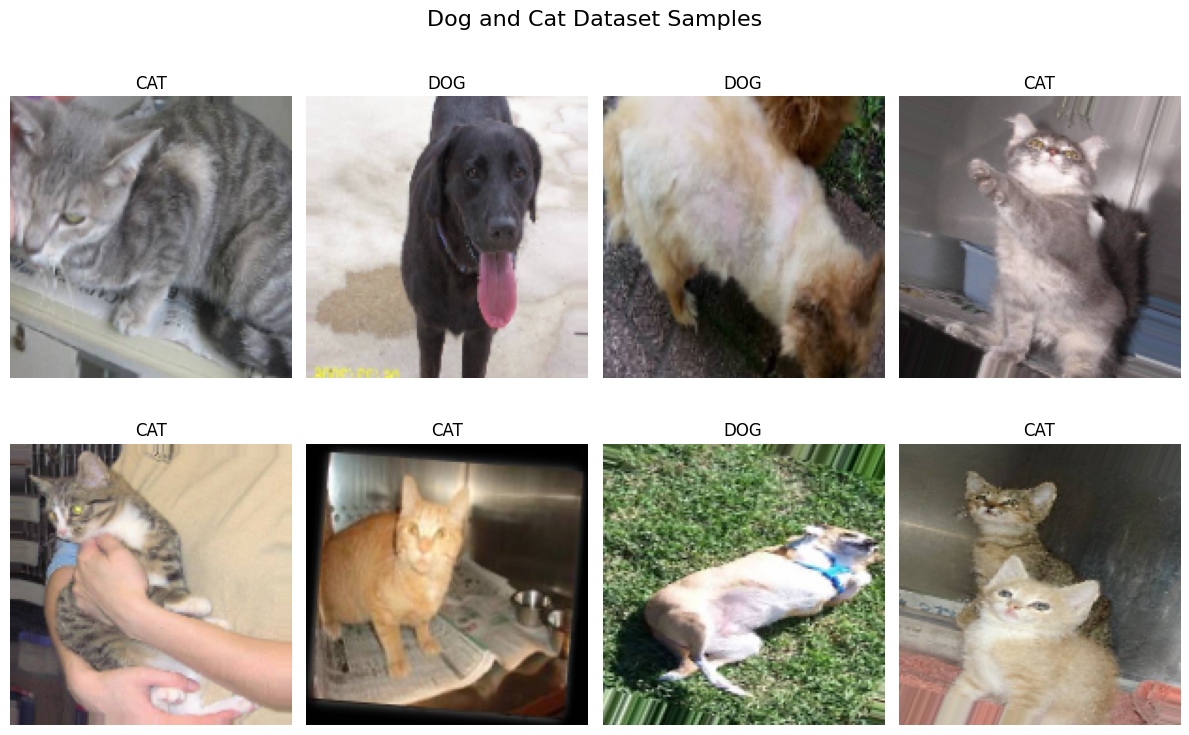

In [ ]:

import matplotlib.pyplot as plt

images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i])

    if labels[i] == 0:
        plt.title("CAT")
    else:
        plt.title("DOG")

    plt.axis("off")

plt.suptitle("Dog and Cat Dataset Samples", fontsize=16)

plt.tight_layout()
plt.show()


In [ ]:


model = models.Sequential([

    layers.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("CNN Model compiled successfully!")


CNN Model compiled successfully!


In [ ]:
EPOCHS = 15

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator
)

print("CNN Model Training Completed!")

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 35s 413ms/step - accuracy: 0.5000 - loss: 0.7335 - val_accuracy: 0.5190 - val_loss: 0.6924
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 277ms/step - accuracy: 0.4960 - loss: 0.6941 - val_accuracy: 0.5000 - val_loss: 0.6944
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 287ms/step - accuracy: 0.5340 - loss: 0.6847 - val_accuracy: 0.5570 - val_loss: 0.6754
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 267ms/step - accuracy: 0.5685 - loss: 0.6673 - val_accuracy: 0.6390 - val_loss: 0.6394
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 279ms/step - accuracy: 0.6205 - loss: 0.6559 - val_accuracy: 0.6420 - val_loss: 0.6254
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 302ms/step - accuracy: 0.6450 - loss: 0.6400 - val_accuracy: 0.6660 - val_loss: 0.6132
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 264ms/step - accuracy: 0.6545 - loss: 0.6250 - val_accuracy: 0.6930 - val_loss: 0.6007
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 280ms/step - accuracy: 0.6770 - loss: 0.6030 - val_accu

In [ ]:
loss, accuracy = model.evaluate(validation_generator)

print("\n========== MODEL EVALUATION ==========")

print("Validation Loss:", round(loss, 4))

print("Validation Accuracy:", round(accuracy * 100, 2), "%")

print("======================================")


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.7330 - loss: 0.5422

========== MODEL EVALUATION ==========
Validation Loss: 0.5422
Validation Accuracy: 73.3 %


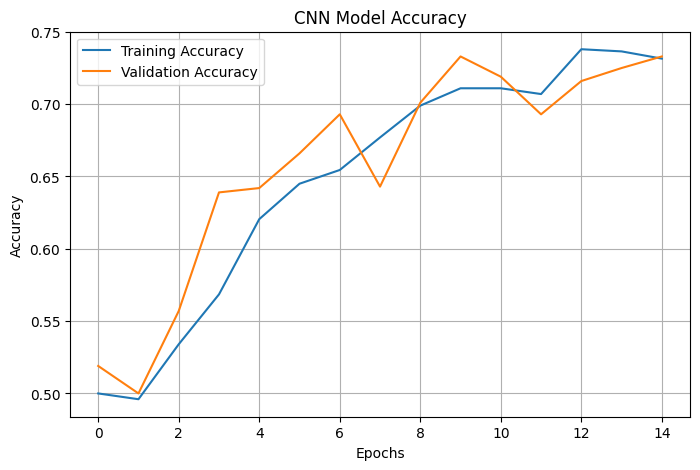

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)

plt.show()


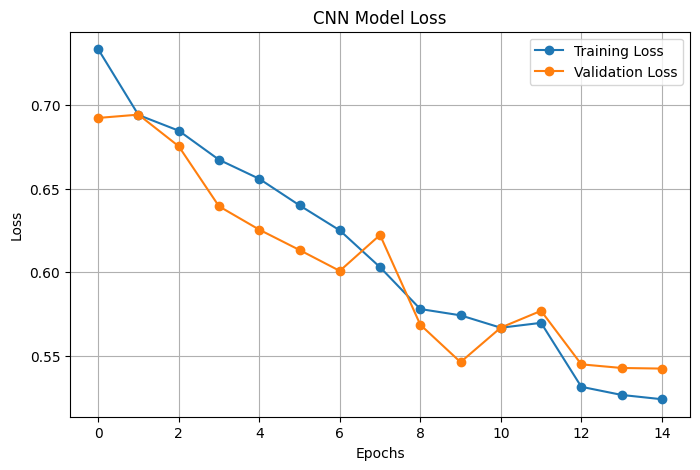

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()


32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step


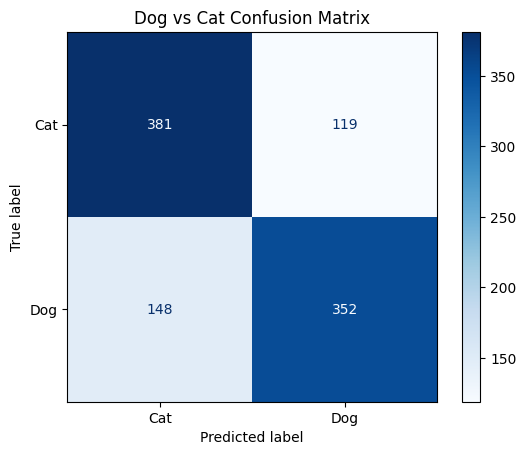


CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cat       0.72      0.76      0.74       500
         Dog       0.75      0.70      0.73       500

    accuracy                           0.73      1000
   macro avg       0.73      0.73      0.73      1000
weighted avg       0.73      0.73      0.73      1000



In [ ]:

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

validation_generator.reset()

predictions = model.predict(validation_generator)

predicted_classes = (predictions >= 0.5).astype(int).flatten()

true_classes = validation_generator.classes

class_names = ['Cat', 'Dog']

cm = confusion_matrix(true_classes, predicted_classes)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(cmap='Blues')

plt.title("Dog vs Cat Confusion Matrix")
plt.show()

print("\nCLASSIFICATION REPORT")

print(classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names
))


In [ ]:

model.save("dog_cat_cnn_model.keras")

print("Model saved successfully!")

print("Model Name: dog_cat_cnn_model.keras")


Model saved successfully!
Model Name: dog_cat_cnn_model.keras


In [ ]:
from google.colab import files

files.download("dog_cat_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving cat.jpeg to cat.jpeg


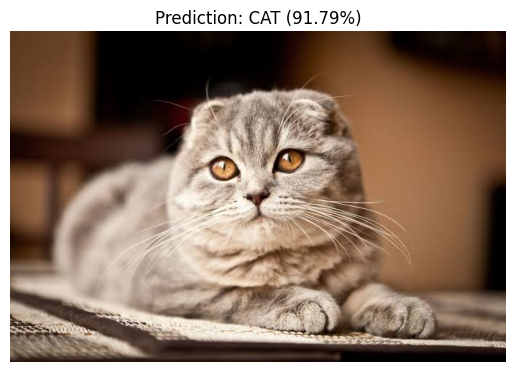

Predicted Class: CAT
Confidence: 91.79 %


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded.keys():

    img = Image.open(filename).convert("RGB")

    img = img.resize((150, 150))

    img_array = np.array(img) / 255.0

    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0][0]

    if prediction >= 0.5:
        result = "DOG"
        confidence = prediction * 100
    else:
        result = "CAT"
        confidence = (1 - prediction) * 100

    plt.imshow(Image.open(filename))
    plt.axis("off")
    plt.title(f"Prediction: {result} ({confidence:.2f}%)")
    plt.show()

    print("Predicted Class:", result)
    print("Confidence:", round(confidence, 2), "%")
